In [2]:
!pip install optbinning

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.8/29.8 MB 74.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [optbinning]


In [3]:
from optbinning import OptimalBinning
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

(CVXPY) Nov 24 11:39:23 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')
(CVXPY) Nov 24 11:39:23 PM: Encountered unexpected exception importing solver GLOP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 24 11:39:23 PM: Encountered unexpected exception importing solver PDLP:
RuntimeError('Unrecognized new version of ortools (9.15.6755). Expected < 9.12.0. Please open a feature request on cvxpy to enable support for this version.')
(CVXPY) Nov 24 11:39:23 PM: Encountered unexpected exception importing solver HIGHS:
ImportError('/usr/local/lib/python3.13/dist-packages/highspy/_core.cpython-313-x86_64-linux-gnu.so: undefined symbol: _ZN5Highs13releaseMemoryEv')


In [27]:
pd.set_option('display.max_columns', None)

In [28]:
pd.set_option('display.max_rows', None)

In [5]:
df=pd.read_csv("dataset_churn_ventanas.csv")
df.head()

,CUSTOMER_ID,VENTANA,TARGET_CHURN,ANTIGUEDAD_MESES,EDAD_CLIENTE,VELOCIDAD_PLAN,RENTA_MENSUAL_6M,CONSUMO_GB_6M,RECLAMOS_3M_6M,RECLAMOS_12M_6M,...,SEXO_UM,CANAL_VENTA_MODE_6M,CANAL_VENTA_MODE_3M,CANAL_VENTA_UM,DISTRITO_MODE_6M,DISTRITO_MODE_3M,DISTRITO_UM,PERIODO_INICIO_PRED,PERIODO_FIN_PRED_EXCL,PERIODO_TARGET
0,CUST_000001,VENTANA1,0,129.0,72.0,50.0,6.479856,384.699198,0.833333,3.333333,...,M,Call Center,Call Center,Call Center,DIST_124,DIST_124,DIST_144,2024-05-01,2024-06-01,2024-07-01
1,CUST_000002,VENTANA1,0,114.0,35.0,100.0,21.568740,467.627357,1.166667,2.666667,...,F,Call Center,Call Center,Call Center,DIST_299,DIST_299,DIST_336,2024-05-01,2024-06-01,2024-07-01
2,CUST_000003,VENTANA1,1,29.0,27.0,50.0,1.319656,140.186348,1.333333,3.166667,...,M,Tienda,Tienda,Tienda,DIST_124,DIST_124,DIST_261,2024-05-01,2024-06-01,2024-07-01
3,CUST_000004,VENTANA1,0,30.0,51.0,100.0,19.436515,217.306448,1.166667,3.166667,...,M,Call Center,Call Center,Call Center,DIST_123,DIST_144,DIST_236,2024-05-01,2024-06-01,2024-07-01
4,CUST_000005,VENTANA1,0,27.0,71.0,300.0,57.571080,226.921120,0.333333,1.833333,...,M,Call Center,Call Center,Call Center,DIST_125,DIST_49,DIST_89,2024-05-01,2024-06-01,2024-07-01


In [15]:
df=df[df['VENTANA']=='VENTANA1']

## Primer ejemplo: RECLAMOS_3M

Aquí utilizaremos una variable numérica.

In [16]:
x = df["RECLAMOS_3M_6M"].values
y = df["TARGET_CHURN"].values

optb = OptimalBinning(
    name="RECLAMOS_3M",
    dtype="numerical",
    max_n_bins=5,
    min_bin_size=0.05,
    monotonic_trend="auto"
)

optb.fit(x, y)

OptimalBinning(max_n_bins=5, min_bin_size=0.05, name='RECLAMOS_3M')

### ¿Qué está haciendo cada parámetro?

Parámetro:	Interpretación

name:	Nombre de la variable

dtype:	Variable numérica

max_n_bins=5	: Máximo de cinco intervalos

min_bin_size=0.05 :	Cada intervalo debe tener al menos 5% de observaciones

monotonic_trend	: Busca una tendencia monotónica cuando corresponde

### ¿Qué significa optimización?

**OptBinning** busca puntos de corte que permitan diferenciar los clientes que abandonan de los que permanecen, considerando las restricciones configuradas.

Generar la tabla Binning

In [17]:
binning_table = optb.binning_table

tabla = binning_table.build()

display(tabla)

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,"(-inf, 0.75)",435,0.485491,381,54,0.124138,0.038172,0.000697,0.000087
1,"[0.75, 0.92)",172,0.191964,144,28,0.162791,-0.278034,0.016432,0.002047
2,"[0.92, 1.25)",201,0.224330,173,28,0.139303,-0.094556,0.002077,0.000260
3,"[1.25, inf)",88,0.098214,83,5,0.056818,0.89376,0.056124,0.006791
4,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
5,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,896,1.000000,781,115,0.128348,,0.075331,0.009185


### ¿Cómo interpretar cada columna?
Columna	:Significado

Bin:	Intervalo encontrado

Count	:Cantidad de clientes

Count (%)	:Participación de clientes

Non-event	:Clientes sin churn

Event	:Clientes con churn

Event rate:	Porcentaje de churn

WoE	:Evidencia a favor de una clase frente a otra

IV	:Capacidad de separación de la variable

JS	: Divergencia entre las distribuciones

### Generar los gráficos
Una de las ventajas de OptBinning es que los gráficos vienen integrados.

Gráfico 1: tasa de eventos

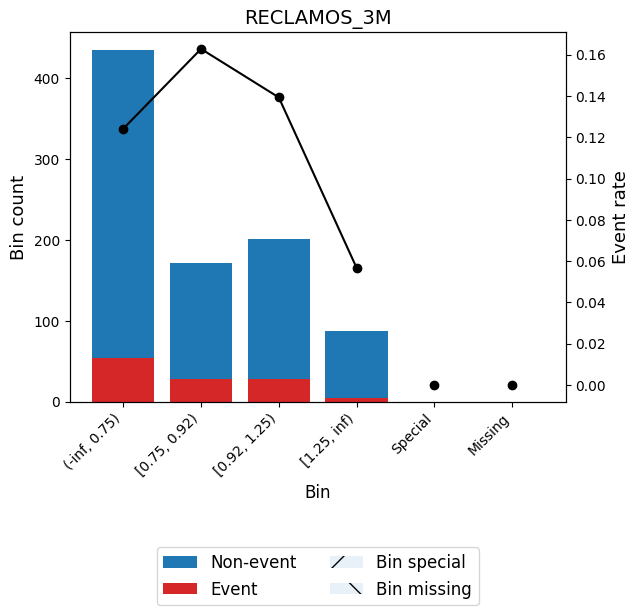

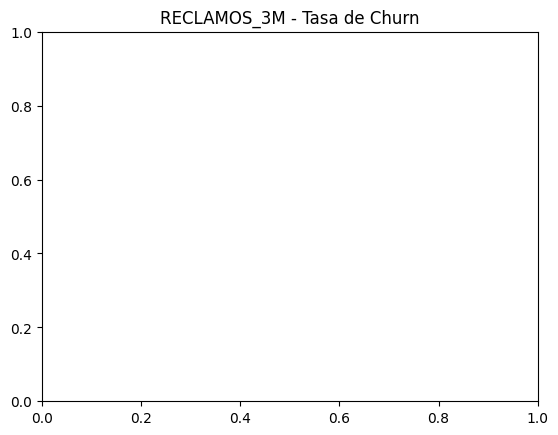

In [19]:
binning_table.plot(
    metric="event_rate",
    show_bin_labels=True
)

plt.title("RECLAMOS_3M - Tasa de Churn")
plt.show()

Interpretación:
- Una tendencia creciente significa que a medida que aumentan los reclamos, también aumenta la tasa de churn.
- Si existe un intervalo con una tasa muy elevada, representa un grupo de clientes de mayor riesgo.
- Si hay oscilaciones, puede existir una relación no monotónica.

Gráfico 2: Weight of Evidence

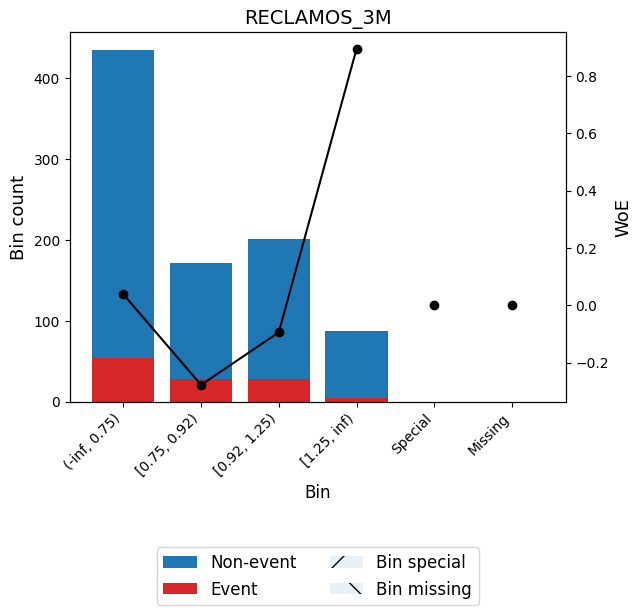

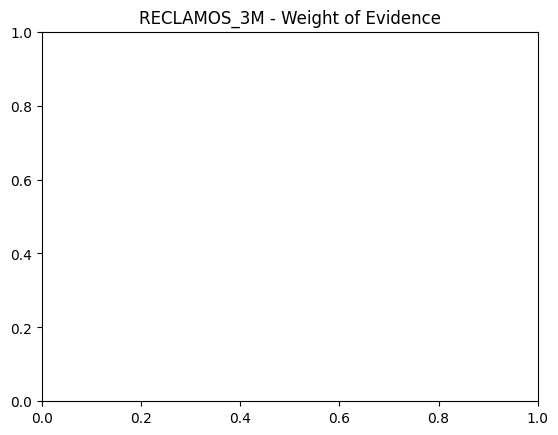

In [20]:
binning_table.plot(
    metric="woe",
    show_bin_labels=True
)

plt.title("RECLAMOS_3M - Weight of Evidence")
plt.show()

Interpretación:
- WoE negativo: el intervalo tiene relativamente más eventos (churn) que no eventos.
- WoE positivo: el intervalo tiene relativamente más no eventos.
- WoE cercano a cero: el intervalo tiene una distribución similar a la población general.

Obtener el IV y realizar análisis estadístico

In [21]:
print("Information Value:", optb.binning_table.iv)

optb.binning_table.analysis()

Information Value: 0.07533051143469977
---------------------------------------------
OptimalBinning: Binary Binning Table Analysis
---------------------------------------------

  General metrics

    Gini index               0.11879976
    IV (Jeffrey)             0.07533051
    JS (Jensen-Shannon)      0.00918506
    Hellinger                0.00929850
    Triangular               0.03588196
    KS                       0.06279575
    HHI                      0.33252202
    HHI (normalized)         0.11002936
    Cramer's V               0.08273386
    Quality score            0.09828827

  Monotonic trend        peak (concave)

  Significance tests

    Bin A  Bin B  t-statistic  p-value  P[A > B]  P[B > A]
        0      1     1.576139 0.209318  0.112069  0.887931
        1      2     0.400727 0.526714  0.736119  0.263881
        2      3     4.116952 0.042456  0.987720  0.012280



Interpretación de las métricas generales:

- Gini index	0.1098	Capacidad discriminatoria baja

- IV (Jeffrey)	0.0439	Poder predictivo bajo

- JS	0.00548	Distribuciones muy similares

- Hellinger	0.00549	Poca separación entre clases
- Triangular	0.02187	Diferencias reducidas
- KS	0.0998	Separación máxima aproximada de 10%
- HHI	0.33398	Concentración de las contribuciones de los bins
- HHI normalized	0.000967	Índice normalizado según la implementación
- Cramer's V	0.0414	Asociación muy débil
- Quality score	0.02738	Calidad global baja según el criterio de OptBinning

Una referencia orientativa para interpretar IV:

IV	Interpretación habitual

* Menor a 0.02	Muy bajo
* 0.02–0.10	Bajo
* 0.10–0.30	Medio
* 0.30–0.50	Alto
* Mayor a 0.50	Revisar posible separación excesiva

Comparación Bin 0 vs Bin 1:
- p-value = 0.8056.
- Es superior a 0.05.
- No encontramos evidencia estadística suficiente para afirmar que las tasas de eventos de ambos bins sean diferentes.
Comparación Bin 1 vs Bin 2
- p-value = 0.2252.
- También es superior a 0.05.
- Tampoco encontramos evidencia estadística suficiente para afirmar que exista una diferencia entre ambos intervalos.
¿Qué significa esto?

Aunque los intervalos tengan tasas de churn diferentes, esas diferencias podrían deberse a variabilidad muestral y no necesariamente a diferencias reales entre grupos.

###¿Qué pasa con las variables categóricas?
También podemos aplicar OptBinning a SEGMENTO.

,Bin,Count,Count (%),Non-event,Event,Event rate,WoE,IV,JS
0,[Pyme],81,0.090402,74,7,0.086420,0.442512,0.014993,0.001859
1,[Masivo],672,0.750000,596,76,0.113095,0.143864,0.014711,0.001837
2,[Premium],143,0.159598,111,32,0.223776,-0.671849,0.091462,0.011223
3,Special,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
4,Missing,0,0.000000,0,0,0.000000,0.0,0.000000,0.000000
Totals,,896,1.000000,781,115,0.128348,,0.121166,0.014919


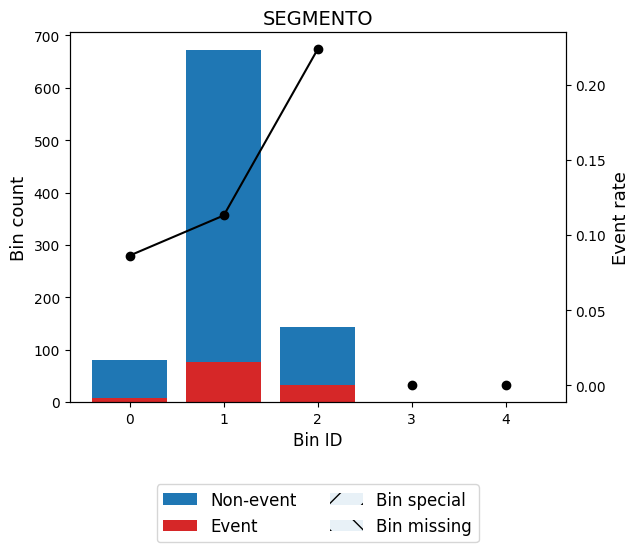

In [22]:
x = df["SEGMENTO_MODE_3M"].values
y = df["TARGET_CHURN"].values

optb_cat = OptimalBinning(
    name="SEGMENTO",
    dtype="categorical",
    max_n_bins=5
)

optb_cat.fit(x, y)

display(optb_cat.binning_table.build())

optb_cat.binning_table.plot(
    metric="event_rate"
)

plt.show()

En este caso, OptBinning agrupará categorías de acuerdo con su comportamiento frente al target.

Por ejemplo, podría encontrar que determinados segmentos presentan tasas de churn similares y agruparlos.

### Automatizar el proceso para todas las variables
Este es el código que utilizarías posteriormente con tu dataset real:

In [23]:
list(df.columns)

['CUSTOMER_ID',
 'VENTANA',
 'TARGET_CHURN',
 'ANTIGUEDAD_MESES',
 'EDAD_CLIENTE',
 'VELOCIDAD_PLAN',
 'RENTA_MENSUAL_6M',
 'CONSUMO_GB_6M',
 'RECLAMOS_3M_6M',
 'RECLAMOS_12M_6M',
 'TICKETS_TECNICOS_6M',
 'CAIDAS_SERVICIO_6M',
 'DIAS_MORA_6M',
 'PAGOS_ATRASADOS_12M_6M',
 'SATISFACCION_6M',
 'VISITAS_WEB_6M',
 'VISITAS_APP_6M',
 'CAMPANIAS_RECIBIDAS_6M',
 'CAMPANIAS_RESPONDIDAS_6M',
 'VELOCIDAD_REAL_6M',
 'USO_STREAMING_6M',
 'USO_GAMING_6M',
 'N_PRODUCTOS_6M',
 'TENURE_ULTIMO_UPGRADE_6M',
 'INGRESO_HOGAR_6M',
 'COMPETENCIA_ZONA_6M',
 'SCORE_RIESGO_6M',
 'CONTACTOS_CALLCENTER_6M',
 'INTERACCIONES_DIGITALES_6M',
 'VELOCIDAD_VARIABILIDAD_6M',
 'DESCUENTO_PCT_6M',
 'USO_NOCTURNO_6M',
 'USO_FIN_SEMANA_6M',
 'FLAG_PREMIUM_FALSO_6M',
 'RENTA_MENSUAL_2_6M',
 'FLAG_EMPRESA_6M',
 'FLAG_CASI_CONSTANTE_6M',
 'RENTA_MENSUAL_3_6M',
 'RECLAMOS_RED_SOCIAL_6M',
 'INTERACCIONES_DIGITALES_SUM_6M',
 'RECLAMOS_RED_SOCIAL_SUM_6M',
 'DIAS_MORA_SUM_6M',
 'RECLAMOS_3M_SUM_6M',
 'CAMPANIAS_RESPONDIDAS_SUM_6M',


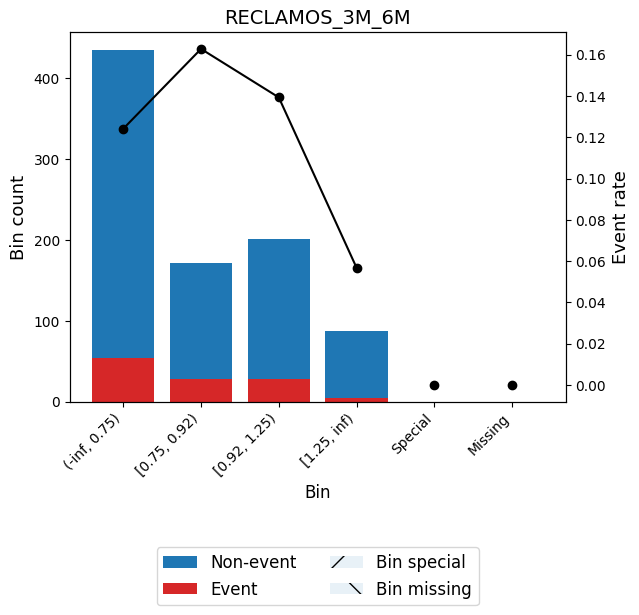


VARIABLE: RECLAMOS_3M_6M
                 Bin  Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 0.75)    435   0.485491        381     54    0.124138   
1       [0.75, 0.92)    172   0.191964        144     28    0.162791   
2       [0.92, 1.25)    201   0.224330        173     28    0.139303   
3        [1.25, inf)     88   0.098214         83      5    0.056818   
4            Special      0   0.000000          0      0    0.000000   
5            Missing      0   0.000000          0      0    0.000000   
Totals                  896   1.000000        781    115    0.128348   

             WoE        IV        JS  
0       0.038172  0.000697  0.000087  
1      -0.278034  0.016432  0.002047  
2      -0.094556  0.002077  0.000260  
3        0.89376  0.056124  0.006791  
4            0.0  0.000000  0.000000  
5            0.0  0.000000  0.000000  
Totals            0.075331  0.009185  
---------------------------------------------
OptimalBinning: Binary Binning Table An

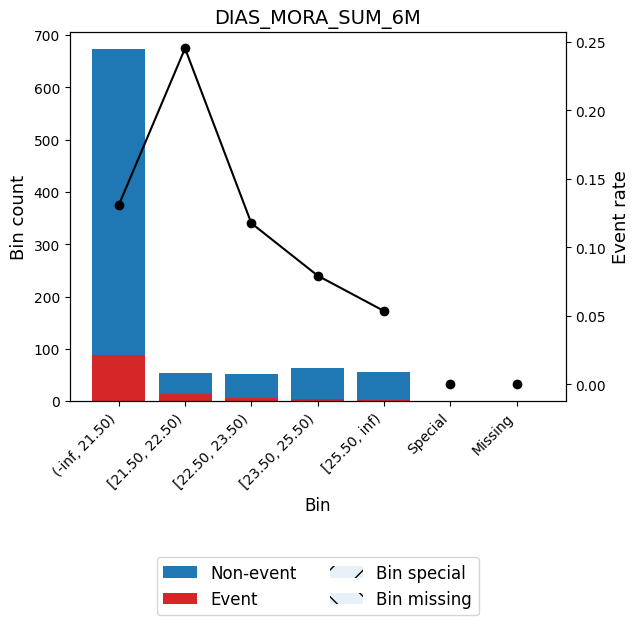


VARIABLE: DIAS_MORA_SUM_6M
                   Bin  Count  Count (%)  Non-event  Event  Event rate  \
0        (-inf, 21.50)    673   0.751116        585     88    0.130758   
1       [21.50, 22.50)     53   0.059152         40     13    0.245283   
2       [22.50, 23.50)     51   0.056920         45      6    0.117647   
3       [23.50, 25.50)     63   0.070312         58      5    0.079365   
4         [25.50, inf)     56   0.062500         53      3    0.053571   
5              Special      0   0.000000          0      0    0.000000   
6              Missing      0   0.000000          0      0    0.000000   
Totals                    896   1.000000        781    115    0.128348   

             WoE        IV        JS  
0      -0.021368  0.000346  0.000043  
1      -0.791713  0.048949  0.005964  
2        0.09926  0.000540  0.000068  
3       0.535362  0.016481  0.002036  
4       0.956037  0.039938  0.004810  
5            0.0  0.000000  0.000000  
6            0.0  0.000000  0.00

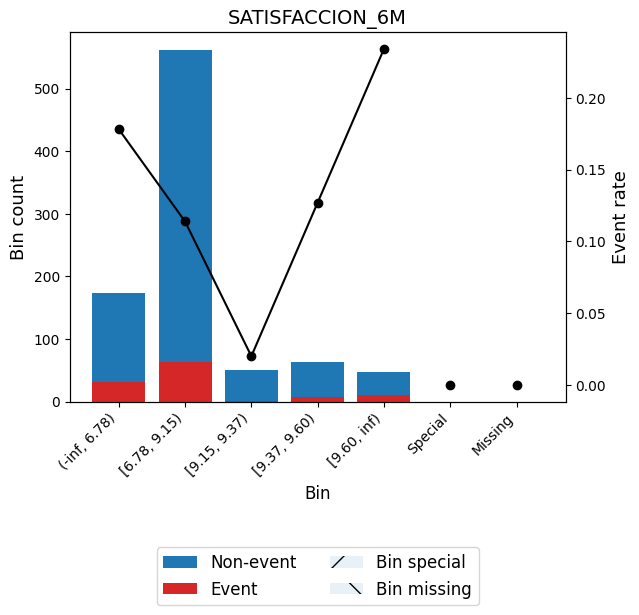


VARIABLE: SATISFACCION_6M
                 Bin  Count  Count (%)  Non-event  Event  Event rate  \
0       (-inf, 6.78)    174   0.194196        143     31    0.178161   
1       [6.78, 9.15)    562   0.627232        498     64    0.113879   
2       [9.15, 9.37)     50   0.055804         49      1    0.020000   
3       [9.37, 9.60)     63   0.070312         55      8    0.126984   
4        [9.60, inf)     47   0.052455         36     11    0.234043   
5            Special      0   0.000000          0      0    0.000000   
6            Missing      0   0.000000          0      0    0.000000   
Totals                  896   1.000000        781    115    0.128348   

             WoE        IV        JS  
0      -0.386786  0.033444  0.004155  
1       0.136074  0.011039  0.001379  
2       1.976177  0.106801  0.011530  
3       0.012249  0.000011  0.000001  
4      -0.730019  0.036178  0.004424  
5            0.0  0.000000  0.000000  
6            0.0  0.000000  0.000000  
Totals      

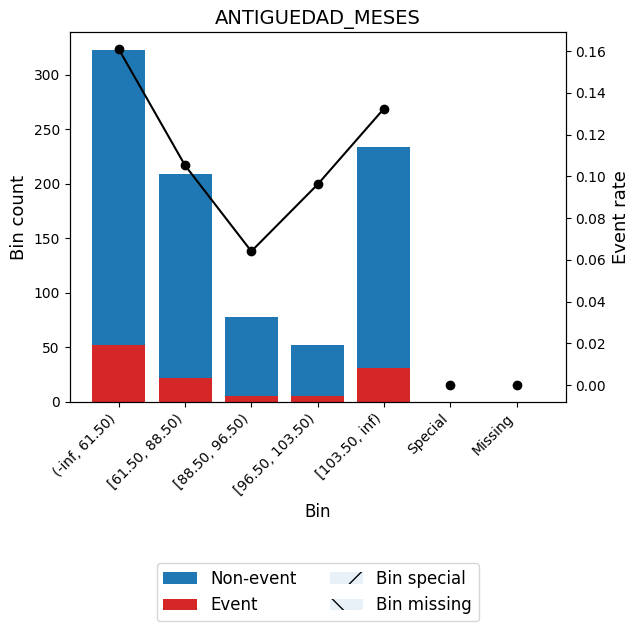


VARIABLE: ANTIGUEDAD_MESES
                    Bin  Count  Count (%)  Non-event  Event  Event rate  \
0         (-inf, 61.50)    323   0.360491        271     52    0.160991   
1        [61.50, 88.50)    209   0.233259        187     22    0.105263   
2        [88.50, 96.50)     78   0.087054         73      5    0.064103   
3       [96.50, 103.50)     52   0.058036         47      5    0.096154   
4         [103.50, inf)    234   0.261161        203     31    0.132479   
5               Special      0   0.000000          0      0    0.000000   
6               Missing      0   0.000000          0      0    0.000000   
Totals                     896   1.000000        781    115    0.128348   

             WoE        IV        JS  
0      -0.264768  0.027849  0.003471  
1       0.224423  0.010802  0.001347  
2       0.765379  0.038263  0.004669  
3       0.325067  0.005429  0.000676  
4      -0.036424  0.000351  0.000044  
5            0.0  0.000000  0.000000  
6            0.0  0.000

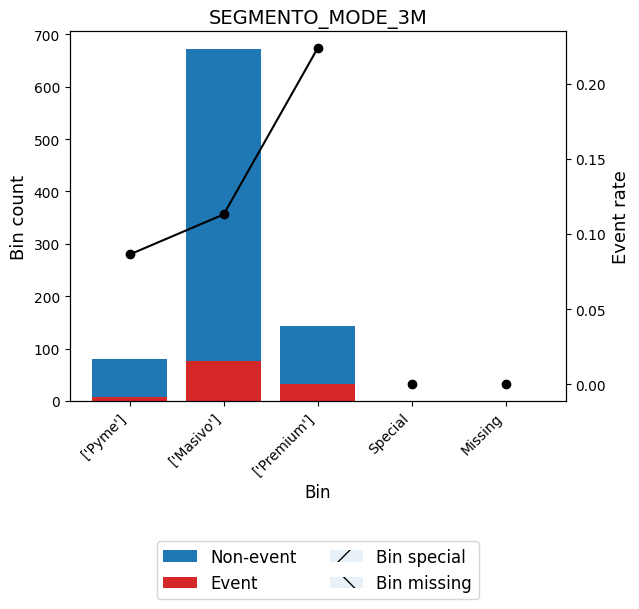


VARIABLE: SEGMENTO_MODE_3M
              Bin  Count  Count (%)  Non-event  Event  Event rate       WoE  \
0          [Pyme]     81   0.090402         74      7    0.086420  0.442512   
1        [Masivo]    672   0.750000        596     76    0.113095  0.143864   
2       [Premium]    143   0.159598        111     32    0.223776 -0.671849   
3         Special      0   0.000000          0      0    0.000000       0.0   
4         Missing      0   0.000000          0      0    0.000000       0.0   
Totals               896   1.000000        781    115    0.128348             

              IV        JS  
0       0.014993  0.001859  
1       0.014711  0.001837  
2       0.091462  0.011223  
3       0.000000  0.000000  
4       0.000000  0.000000  
Totals  0.121166  0.014919  
---------------------------------------------
OptimalBinning: Binary Binning Table Analysis
---------------------------------------------

  General metrics

    Gini index               0.15230195
    IV (Jeffrey) 

,VARIABLE,IV,N_BINS
2,SATISFACCION_6M,0.187472,4
4,SEGMENTO_MODE_3M,0.121166,3
1,DIAS_MORA_SUM_6M,0.106255,4
3,ANTIGUEDAD_MESES,0.082694,4
0,RECLAMOS_3M_6M,0.075331,3


In [24]:

from optbinning import OptimalBinning
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

target = "TARGET_CHURN"

variables = [
    "RECLAMOS_3M_6M",
    "DIAS_MORA_SUM_6M",
    "SATISFACCION_6M",
    "ANTIGUEDAD_MESES",
    "SEGMENTO_MODE_3M"
]

os.makedirs("graficos_binning", exist_ok=True)

resultados = {}
resumen = []

for variable in variables:

    temp = df[[variable, target]].dropna()

    x = temp[variable].values
    y = temp[target].values

    dtype = (
        "categorical"
        if temp[variable].dtype == "object"
        else "numerical"
    )

    optb = OptimalBinning(
        name=variable,
        dtype=dtype,
        max_n_bins=5,
        min_bin_size=0.05
        if dtype == "numerical" else None
    )

    optb.fit(x, y)

    # Tabla
    tabla = optb.binning_table.build()

    resultados[variable] = tabla

    # Resumen IV
    resumen.append({
        "VARIABLE": variable,
        "IV": optb.binning_table.iv,
        "N_BINS": len(optb.splits)
        if dtype == "numerical"
        else len(optb.splits)
    })

    # Gráfico de tasa de churn
    optb.binning_table.plot(
        metric="event_rate",
        show_bin_labels=True
    )

    plt.title(f"{variable} - Event Rate")
    plt.tight_layout()

    plt.savefig(
        f"graficos_binning/{variable}.png",
        dpi=150
    )

    plt.close()

    print(f"\nVARIABLE: {variable}")
    print(tabla)

    optb.binning_table.analysis()

# Ranking de variables
ranking_iv = (
    pd.DataFrame(resumen)
    .sort_values("IV", ascending=False)
)

display(ranking_iv)


¿Qué observamos?
- Pyme: presenta una tasa de churn de 9.96%, inferior al promedio general (11.37%).
- Masivo: presenta una tasa de 11%, bastante cercana al promedio.
- Premium: presenta una tasa de 13.95%, superior al promedio.
Desde el punto de vista del negocio, Premium parece ser el segmento con mayor propensión al abandono.

Por ejemplo, su tasa de churn es aproximadamente 1.40 veces la de Pyme.

Esto es una diferencia descriptiva; todavía no demuestra que pertenecer a Premium provoque mayor churn.

### Qué nos dice el WoE?
El WoE (Weight of Evidence) nos permite observar qué tan diferente es la distribución de clientes que abandonan respecto a la distribución de clientes que permanecen.

Tus resultados son:
Segmento	WoE	Interpretación
Pyme	0.1487	Ligeramente asociado con menor churn
Masivo	0.0376	Muy cercano al comportamiento promedio
Premium	-0.2335	Ligeramente asociado con mayor churn

En este resultado, el signo negativo de Premium indica que su distribución relativa de eventos es mayor que la de no eventos, según la convención de WoE utilizada por OptBinning.

La lectura sencilla sería:
- WoE positivo: mayor representación relativa de clientes que permanecen.
- WoE negativo: mayor representación relativa de clientes que abandonan.
- WoE cercano a cero: comportamiento similar al promedio.

### ¿Qué nos dice el IV (Information Value)?
IV total: 0.0124
Este es uno de los indicadores más importantes para evaluar la capacidad de separación de la variable.

Como referencia orientativa:
IV	Interpretación habitual
Menor a 0.02	Muy bajo
0.02 – 0.10	Bajo
0.10 – 0.30	Medio
0.30 – 0.50	Alto
Mayor a 0.50	Revisar posible sobreajuste o fuga de información

Tu resultado:
\[
IV = 0.012405
\]

Esto significa que SEGMENTO_MODE_3M tiene una capacidad de separación muy baja entre eventos y no eventos.

¿Por qué?

Porque, aunque Premium presenta una tasa de churn superior, las diferencias entre los tres segmentos no son suficientemente grandes como para que esta variable discrimine fuertemente por sí sola.

Por ejemplo, observa que:
- Pyme tiene 9.96% de churn.
- Masivo tiene 11%.
- Premium tiene 13.95%.
Las diferencias existen, pero no son muy pronunciadas.

### ¿Qué nos dice el JS (Jensen-Shannon)?
Tu resultado:
\[
JS = 0.001548
\]

Es un valor bastante cercano a cero.

Esto indica que las distribuciones de eventos y no eventos entre los segmentos son muy parecidas.

En términos sencillos:

Si comparamos cómo se distribuyen los clientes que abandonan y los que permanecen entre Pyme, Masivo y Premium, encontramos pocas diferencias.

Por eso, el JS confirma lo que ya observamos con el IV: la variable tiene poca capacidad de separación.

### ¿Qué significan las categorías Special y Missing?
En tu tabla aparecen:
Categoría	Clientes
Special	0
Missing	0

Esto significa que no existen registros que OptBinning haya clasificado como valores especiales o faltantes en esta variable.

No hay nada que interpretar en esas dos categorías.

### ¿Debería eliminar esta variable de mi modelo LightGBM?
Aquí viene una consideración importante .

No eliminaría automáticamente SEGMENTO_MODE_3M solamente porque su IV sea 0.0124.

Recuerda que el IV mide la capacidad de separación individual de una variable, pero LightGBM puede encontrar interacciones entre variables.

Por ejemplo:
- Premium + antigüedad baja.
- Premium + reclamos frecuentes.
- Premium + reducción del consumo.
- Premium + aumento de la renta mensual.
Quizás SEGMENTO_MODE_3M tenga poca capacidad predictiva por sí sola, pero sea útil cuando se combina con otras variables.

### conclusión para la variable
IV = 0.0124

Capacidad predictiva individual muy baja
- Premium presenta la mayor tasa de churn (13.95%).
- Pyme presenta la menor tasa de churn (9.96%).
- Masivo concentra el 75% de los clientes.
- Las distribuciones de eventos y no eventos son bastante similares (JS = 0.00155).

Recomendación: conservarla inicialmente y evaluar su aporte dentro de LightGBM mediante permutation importance y shap values.

observación: tienes 303 eventos en 2,664 clientes, lo que representa una tasa de churn del 11.37%. Es una cantidad de eventos razonable para analizar los segmentos, pero recuerda que Pyme tiene solo 24 eventos. Por eso, conviene no sobreinterpretar las diferencias de ese grupo sin evaluar su incertidumbre estadística.

In [25]:
from sklearn.feature_selection import mutual_info_classif
from optbinning import OptimalBinning


def calcular_mi_iv(df, target):

    # Variables predictoras
    X = df.drop(columns=[target])
    y = df[target]

    # Seleccionar solo variables numéricas para MI
    X_num = X.select_dtypes(include=np.number)

    # Reemplazar infinitos
    X_num = X_num.replace([np.inf, -np.inf], np.nan)

    # Imputación simple para MI
    X_num = X_num.fillna(X_num.median())

    # Mutual Information
    mi = mutual_info_classif(
        X_num,
        y,
        discrete_features=False,
        random_state=42
    )

    mi_df = pd.DataFrame({
        "variable": X_num.columns,
        "mutual_information": mi
    })

    # Information Value
    iv_list = []

    for col in X.columns:
        try:
            x = df[col]

            optb = OptimalBinning(
                name=col,
                dtype="numerical" if pd.api.types.is_numeric_dtype(x) else "categorical"
            )

            optb.fit(x, y)

            iv = optb.binning_table.build()["IV"].iloc[0]

        except Exception:
            iv = np.nan

        iv_list.append({
            "variable": col,
            "information_value": iv
        })

    iv_df = pd.DataFrame(iv_list)

    # Unir MI e IV
    resultado = (
        iv_df
        .merge(mi_df, on="variable", how="left")
        .sort_values(
            ["information_value", "mutual_information"],
            ascending=False
        )
        .reset_index(drop=True)
    )

    return resultado

df_metricas = calcular_mi_iv(df, target="TARGET_CHURN")

print(df_metricas)


                      variable  information_value  mutual_information
0             DISTRITO_MODE_6M           1.723901                 NaN
1                  DISTRITO_UM           1.318589                 NaN
2             DISTRITO_MODE_3M           1.209703                 NaN
3    VELOCIDAD_VARIABILIDAD_UM           0.106101            0.016637
4                CONSUMO_GB_3M           0.091472            0.014343
..                         ...                ...                 ...
148                CUSTOMER_ID           0.000000                 NaN
149                    VENTANA           0.000000                 NaN
150        PERIODO_INICIO_PRED           0.000000                 NaN
151      PERIODO_FIN_PRED_EXCL           0.000000                 NaN
152             PERIODO_TARGET           0.000000                 NaN

[153 rows x 3 columns]


In [29]:
df_metricas

,variable,information_value,mutual_information
0,DISTRITO_MODE_6M,1.723901,NaN
1,DISTRITO_UM,1.318589,NaN
2,DISTRITO_MODE_3M,1.209703,NaN
3,VELOCIDAD_VARIABILIDAD_UM,0.106101,0.016637
4,CONSUMO_GB_3M,0.091472,0.014343
5,VELOCIDAD_REAL_UM,0.085994,0.011871
6,INTERACCIONES_DIGITALES_SUM_3M,0.067920,0.016795
7,INTERACCIONES_DIGITALES_3M,0.067920,0.000898
8,CONSUMO_GB_6M,0.057397,0.004415
9,INTERACCIONES_DIGITALES_UM,0.057110,0.015638
